<a href="https://colab.research.google.com/github/umamaheshdev01/Matplotlib/blob/main/matplotlib_seaborn_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📊 Matplotlib & Seaborn — Complete Learning Guide

> **Matplotlib** is Python's core plotting library — full control over every detail.
> **Seaborn** is built on top of Matplotlib and makes beautiful statistical plots with less code.
>
> **Rule of thumb:** Use Seaborn for quick, beautiful stats plots. Use Matplotlib when you need fine-grained control.

---
## 📚 Table of Contents

### Matplotlib
1. [Setup & The Two Interfaces](#1-setup--the-two-interfaces)
2. [Line Plot](#2-line-plot)
3. [Scatter Plot](#3-scatter-plot)
4. [Bar Chart](#4-bar-chart)
5. [Histogram](#5-histogram)
6. [Pie Chart](#6-pie-chart)
7. [Subplots (Multiple Plots)](#7-subplots-multiple-plots)
8. [Plot Styling & Customization](#8-plot-styling--customization)
9. [Saving Figures](#9-saving-figures)

### Seaborn
10. [Setup & Sample Datasets](#10-setup--sample-datasets)
11. [Distribution Plots](#11-distribution-plots)
12. [Categorical Plots](#12-categorical-plots)
13. [Relationship Plots](#13-relationship-plots)
14. [Heatmap & Correlation](#14-heatmap--correlation)
15. [Pair Plot](#15-pair-plot)
16. [Styling & Themes](#16-styling--themes)

### Combined
17. [Practical Mini-Projects](#17-practical-mini-projects)

---
## 1. Setup & The Two Interfaces

> Matplotlib has **two ways** to plot:
> - **pyplot interface** (`plt.plot(...)`) — quick & simple, like MATLAB
> - **Object-Oriented (OO) interface** (`fig, ax = plt.subplots()`) — more control, **recommended for serious work**

In [2]:
# Install if needed:
# !pip install matplotlib seaborn numpy pandas

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

# Show plots inline in Jupyter
%matplotlib inline

print("Matplotlib version:", mpl.__version__)
print("Seaborn version   :", sns.__version__)

Matplotlib version: 3.10.0
Seaborn version   : 0.13.2


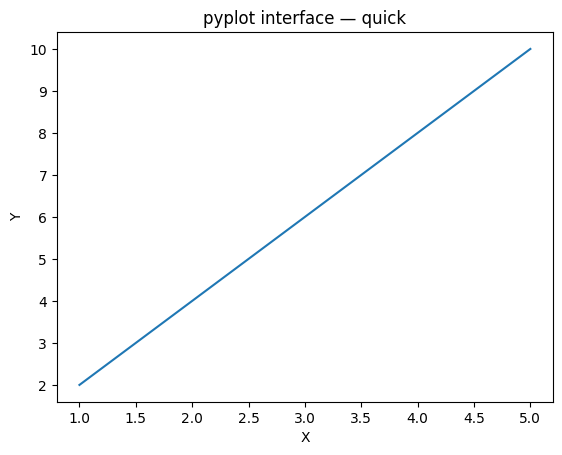

In [2]:
# ─────────────────────────────────────────────────
# 🅐  pyplot interface  (quick & dirty)
# ─────────────────────────────────────────────────
x = [1, 2, 3, 4, 5]
y = [2, 4, 6, 8, 10]

plt.plot(x, y)
plt.title("pyplot interface — quick")
plt.xlabel("X")
plt.ylabel("Y")
plt.show()

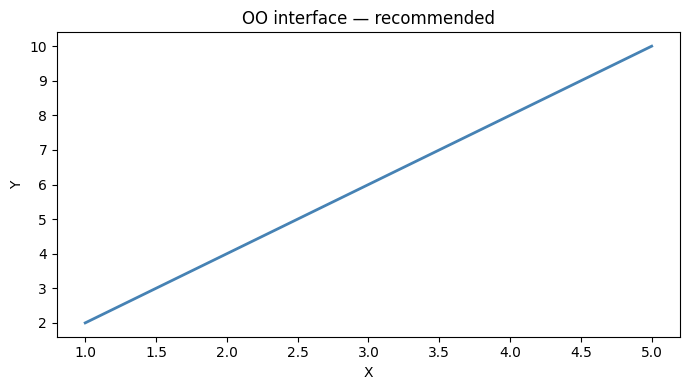

In [5]:
# ─────────────────────────────────────────────────
# 🅑  Object-Oriented interface  (recommended)
# ─────────────────────────────────────────────────
# fig  = the whole canvas / window
# ax   = one individual plot panel inside the canvas

fig, ax = plt.subplots(figsize=(7, 4))  # figsize = (width, height) in inches

ax.plot(x, y, color='steelblue', linewidth=2)
ax.set_title("OO interface — recommended")
ax.set_xlabel("X")
ax.set_ylabel("Y")

plt.tight_layout()   # Prevent labels from getting clipped
plt.show()

---
## 2. Line Plot
> Best for: **trends over time**, continuous data.

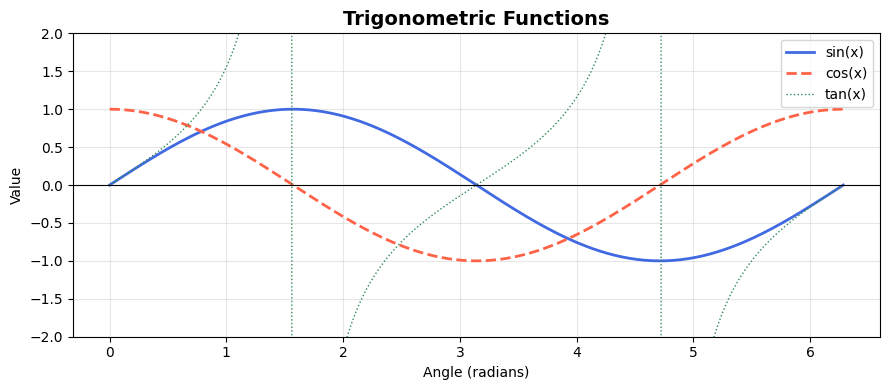

In [6]:
x = np.linspace(0, 2 * np.pi, 300)   # 300 points from 0 to 2π

fig, ax = plt.subplots(figsize=(9, 4))

# Plot multiple lines on the same axes
ax.plot(x, np.sin(x), label='sin(x)',  color='royalblue',  linewidth=2)
ax.plot(x, np.cos(x), label='cos(x)',  color='tomato',     linewidth=2, linestyle='--')
ax.plot(x, np.tan(x), label='tan(x)',  color='seagreen',   linewidth=1, linestyle=':')

# ── Key customizations ──
ax.set_title('Trigonometric Functions', fontsize=14, fontweight='bold')
ax.set_xlabel('Angle (radians)')
ax.set_ylabel('Value')
ax.set_ylim(-2, 2)             # Clip the y-axis (tan blows up)
ax.axhline(0, color='black', linewidth=0.8, linestyle='-')  # Horizontal zero line
ax.legend(loc='upper right')   # Add legend
ax.grid(True, alpha=0.3)       # Subtle grid

plt.tight_layout()
plt.show()

# ── linestyle shortcuts ──
# '-'  solid  |  '--'  dashed  |  ':'  dotted  |  '-.'  dash-dot

---
## 3. Scatter Plot
> Best for: **relationships between two numeric variables**, spotting clusters.

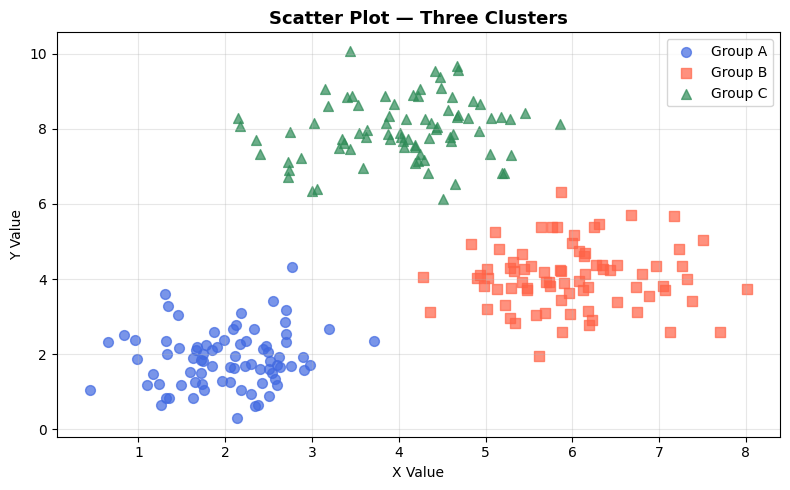

In [7]:
rng = np.random.default_rng(42)

# Generate three clusters of points
n = 80
x1, y1 = rng.normal(2, 0.8, n),  rng.normal(2, 0.8, n)   # Cluster A
x2, y2 = rng.normal(6, 0.8, n),  rng.normal(4, 0.8, n)   # Cluster B
x3, y3 = rng.normal(4, 0.8, n),  rng.normal(8, 0.8, n)   # Cluster C

fig, ax = plt.subplots(figsize=(8, 5))

# scatter(x, y, s=size, c=color, alpha=opacity, marker=shape)
ax.scatter(x1, y1, s=50, c='royalblue', alpha=0.7, label='Group A', marker='o')
ax.scatter(x2, y2, s=50, c='tomato',    alpha=0.7, label='Group B', marker='s')  # square
ax.scatter(x3, y3, s=50, c='seagreen',  alpha=0.7, label='Group C', marker='^')  # triangle

ax.set_title('Scatter Plot — Three Clusters', fontsize=13, fontweight='bold')
ax.set_xlabel('X Value')
ax.set_ylabel('Y Value')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ── marker options ──
# 'o' circle | 's' square | '^' triangle | 'D' diamond | '*' star | '+' plus

---
## 4. Bar Chart
> Best for: **comparing categories**.

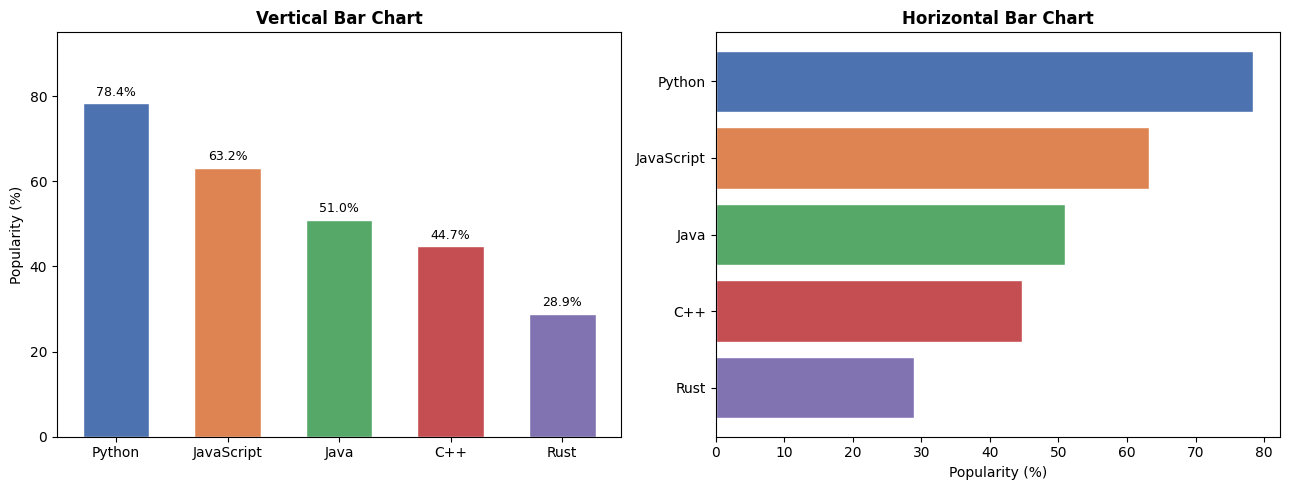

In [8]:
categories = ['Python', 'JavaScript', 'Java', 'C++', 'Rust']
popularity = [78.4, 63.2, 51.0, 44.7, 28.9]
colors     = ['#4c72b0', '#dd8452', '#55a868', '#c44e52', '#8172b2']

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# ── Vertical Bar Chart ──
bars = axes[0].bar(categories, popularity, color=colors, edgecolor='white', width=0.6)
axes[0].set_title('Vertical Bar Chart', fontweight='bold')
axes[0].set_ylabel('Popularity (%)')
axes[0].set_ylim(0, 95)

# Add value labels on top of each bar
for bar in bars:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, h + 1,
                 f'{h}%', ha='center', va='bottom', fontsize=9)

# ── Horizontal Bar Chart ──
axes[1].barh(categories, popularity, color=colors, edgecolor='white')
axes[1].set_title('Horizontal Bar Chart', fontweight='bold')
axes[1].set_xlabel('Popularity (%)')
axes[1].invert_yaxis()   # Highest at the top

plt.tight_layout()
plt.show()

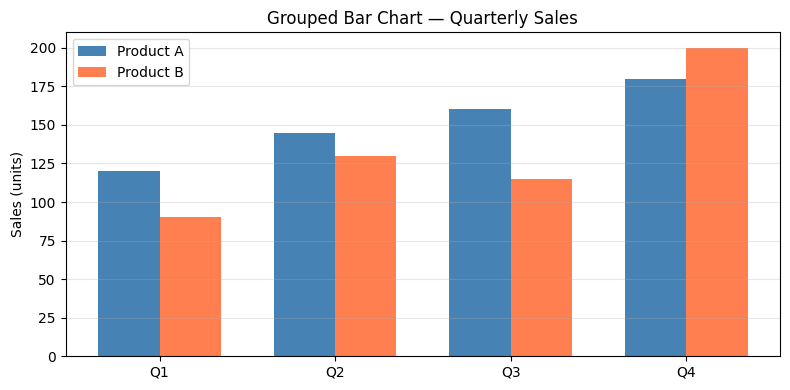

In [9]:
# ── Grouped Bar Chart ──
quarters = ['Q1', 'Q2', 'Q3', 'Q4']
product_a = [120, 145, 160, 180]
product_b = [ 90, 130, 115, 200]

x = np.arange(len(quarters))   # [0, 1, 2, 3]
width = 0.35                    # Width of each bar

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x - width/2, product_a, width, label='Product A', color='steelblue')
ax.bar(x + width/2, product_b, width, label='Product B', color='coral')

ax.set_title('Grouped Bar Chart — Quarterly Sales')
ax.set_xticks(x)
ax.set_xticklabels(quarters)
ax.set_ylabel('Sales (units)')
ax.legend()
ax.grid(axis='y', alpha=0.3)   # Grid only on y-axis

plt.tight_layout()
plt.show()

---
## 5. Histogram
> Best for: **visualizing the distribution** of a single numeric variable.

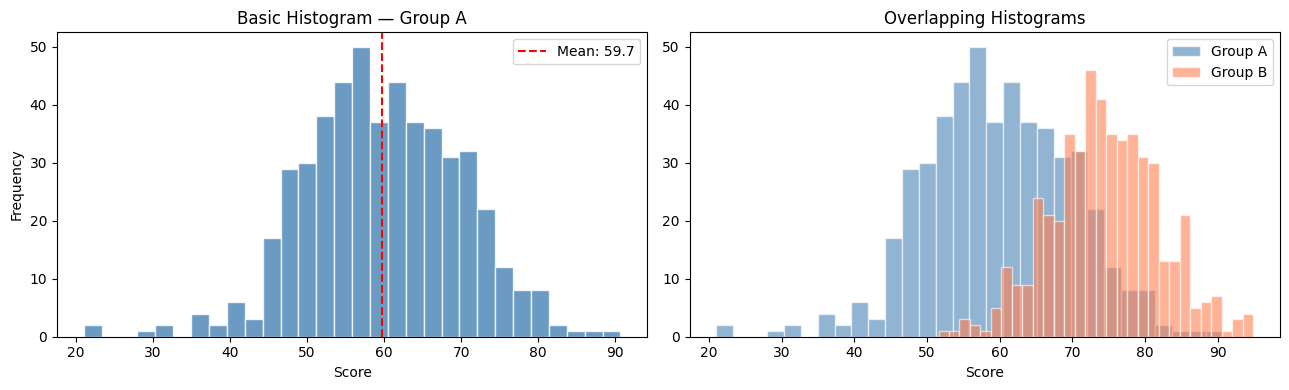

In [10]:
rng = np.random.default_rng(0)
data_a = rng.normal(loc=60, scale=10, size=500)   # Group A: mean=60
data_b = rng.normal(loc=75, scale=8,  size=500)   # Group B: mean=75

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# ── Basic Histogram ──
# bins=number of bars | edgecolor adds outline | density=True normalizes to probability
axes[0].hist(data_a, bins=30, color='steelblue', edgecolor='white', alpha=0.8)
axes[0].set_title('Basic Histogram — Group A')
axes[0].set_xlabel('Score')
axes[0].set_ylabel('Frequency')
axes[0].axvline(np.mean(data_a), color='red', linestyle='--', label=f'Mean: {np.mean(data_a):.1f}')
axes[0].legend()

# ── Overlapping Histograms (great for comparison) ──
axes[1].hist(data_a, bins=30, color='steelblue', alpha=0.6, label='Group A', edgecolor='white')
axes[1].hist(data_b, bins=30, color='coral',     alpha=0.6, label='Group B', edgecolor='white')
axes[1].set_title('Overlapping Histograms')
axes[1].set_xlabel('Score')
axes[1].legend()

plt.tight_layout()
plt.show()

---
## 6. Pie Chart
> Best for: **part-to-whole** relationships (use sparingly — bar charts are usually clearer).

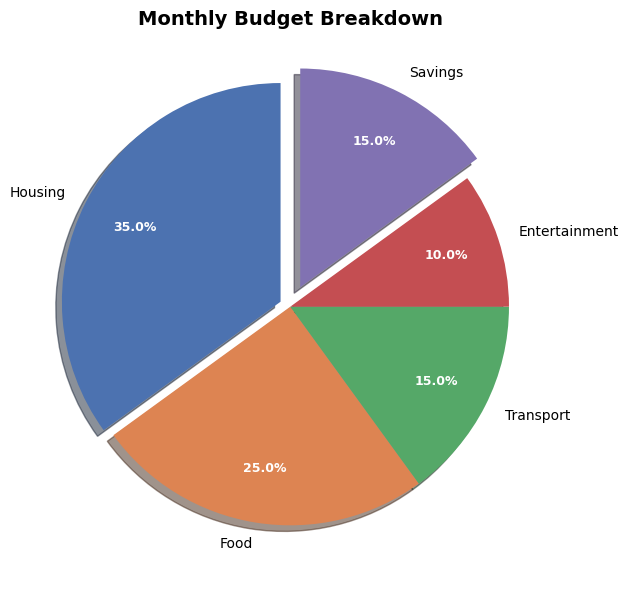

In [3]:
labels  = ['Housing', 'Food', 'Transport', 'Entertainment', 'Savings']
sizes   = [35, 25, 15, 10, 15]
colors  = ['#4c72b0', '#dd8452', '#55a868', '#c44e52', '#8172b2']
explode = [0.05, 0, 0, 0, 0.1]   # Slightly pull out Housing and Savings

fig, ax = plt.subplots(figsize=(7, 6))

wedges, texts, autotexts = ax.pie(
    sizes,
    labels=labels,
    colors=colors,
    explode=explode,
    autopct='%1.1f%%',      # Show percentage inside slices
    startangle=90,          # Start from top
    pctdistance=0.75,       # Distance of % text from center
    shadow=True             # Adds drop shadow
)

# Style the percentage text
for autotext in autotexts:
    autotext.set_fontsize(9)
    autotext.set_color('white')
    autotext.set_fontweight('bold')

ax.set_title('Monthly Budget Breakdown', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 7. Subplots (Multiple Plots)
> Display multiple plots in a grid layout — the most useful layout tool.

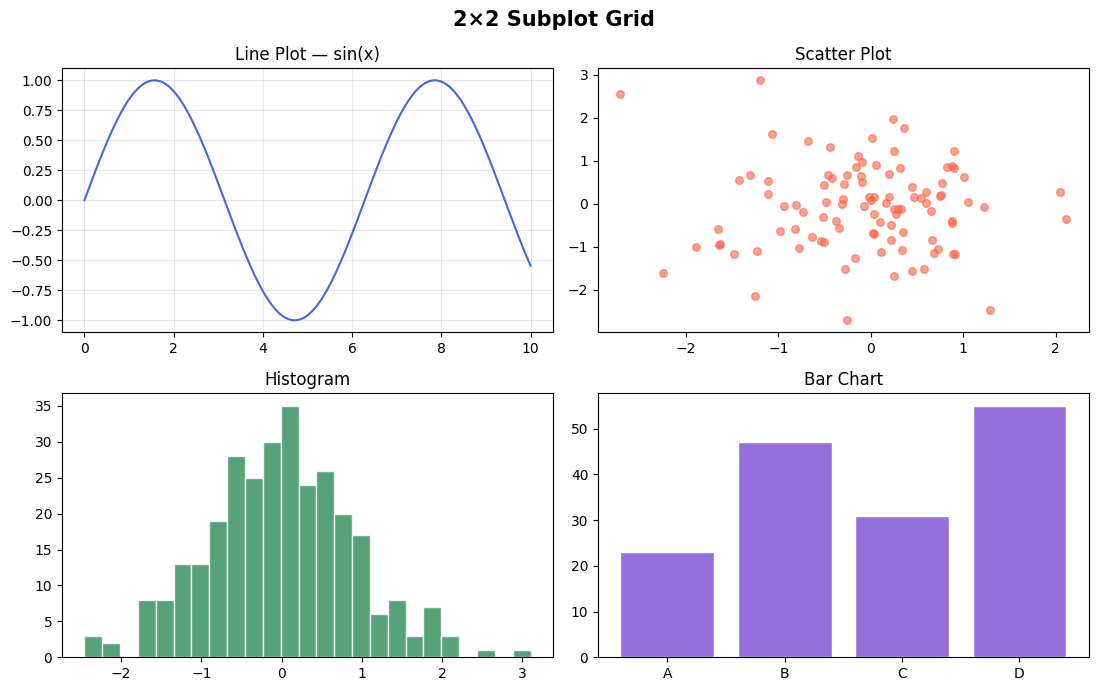

In [4]:
x = np.linspace(0, 10, 200)
rng = np.random.default_rng(1)

# ── 2×2 Grid of Subplots ──
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(11, 7))
fig.suptitle('2×2 Subplot Grid', fontsize=15, fontweight='bold')   # Main title

# Top-left
axes[0, 0].plot(x, np.sin(x), color='royalblue')
axes[0, 0].set_title('Line Plot — sin(x)')
axes[0, 0].grid(alpha=0.3)

# Top-right
axes[0, 1].scatter(rng.normal(size=100), rng.normal(size=100),
                   alpha=0.6, color='tomato', s=30)
axes[0, 1].set_title('Scatter Plot')

# Bottom-left
data = rng.normal(size=300)
axes[1, 0].hist(data, bins=25, color='seagreen', edgecolor='white', alpha=0.8)
axes[1, 0].set_title('Histogram')

# Bottom-right
cats   = ['A', 'B', 'C', 'D']
values = [23, 47, 31, 55]
axes[1, 1].bar(cats, values, color='mediumpurple', edgecolor='white')
axes[1, 1].set_title('Bar Chart')

plt.tight_layout()
plt.show()

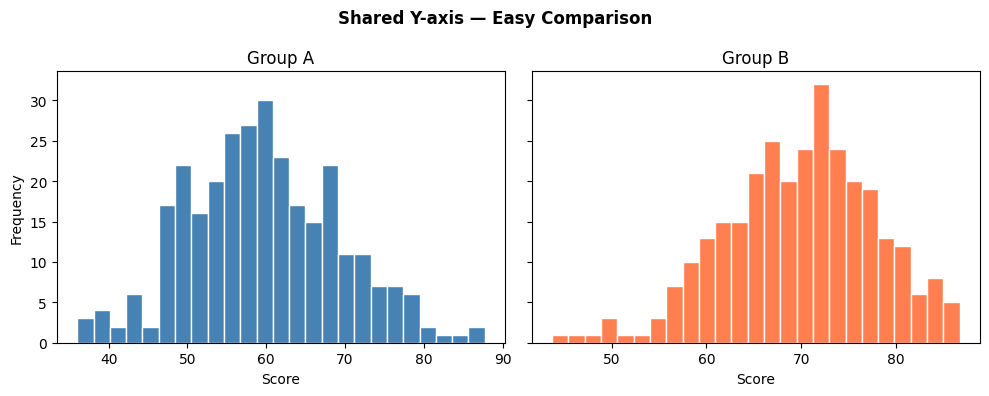

In [5]:
# ── Shared Axes (great for comparing scales) ──
fig, (ax1, ax2) = plt.subplots(1, 2,
                                figsize=(10, 4),
                                sharey=True)   # Both plots share the same Y axis

rng = np.random.default_rng(5)
ax1.hist(rng.normal(60, 10, 300), bins=25, color='steelblue', edgecolor='white')
ax1.set_title('Group A')
ax1.set_xlabel('Score')
ax1.set_ylabel('Frequency')

ax2.hist(rng.normal(70, 8,  300), bins=25, color='coral', edgecolor='white')
ax2.set_title('Group B')
ax2.set_xlabel('Score')

fig.suptitle('Shared Y-axis — Easy Comparison', fontweight='bold')
plt.tight_layout()
plt.show()

---
## 8. Plot Styling & Customization
> The difference between a rough draft and a publication-ready figure.

In [6]:
# ── Available Built-in Styles ──
print("Available styles:", plt.style.available[:10], "...")  # Show first 10

Available styles: ['Solarize_Light2', '_classic_test_patch', '_mpl-gallery', '_mpl-gallery-nogrid', 'bmh', 'classic', 'dark_background', 'fast', 'fivethirtyeight', 'ggplot'] ...


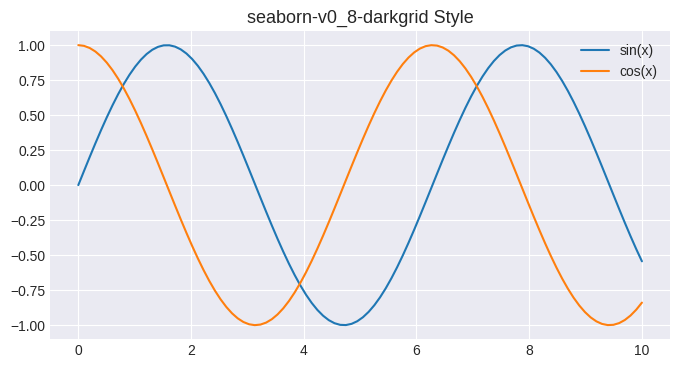

In [7]:
# ── Applying a Style ──
with plt.style.context('seaborn-v0_8-darkgrid'):   # Apply temporarily
    x = np.linspace(0, 10, 100)
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(x, np.sin(x), label='sin(x)')
    ax.plot(x, np.cos(x), label='cos(x)')
    ax.set_title('seaborn-v0_8-darkgrid Style', fontsize=13)
    ax.legend()
    plt.show()

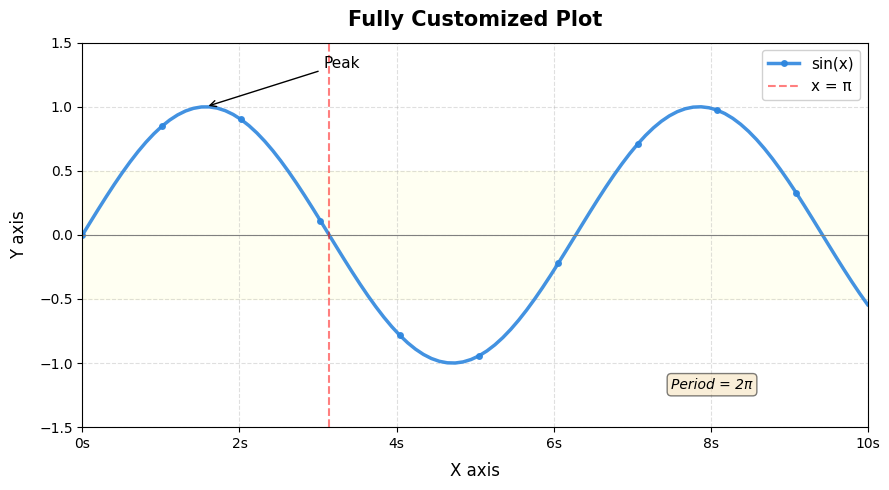

In [8]:
# ── Comprehensive Customization Reference ──
x = np.linspace(0, 10, 100)

fig, ax = plt.subplots(figsize=(9, 5))

line, = ax.plot(x, np.sin(x),
                color='#2e86de',    # Hex color
                linewidth=2.5,
                linestyle='-',
                marker='o',         # Show markers
                markersize=4,
                markevery=10,       # Show marker every 10th point
                label='sin(x)',
                alpha=0.9)

# ── Titles & Labels ──
ax.set_title('Fully Customized Plot', fontsize=15, fontweight='bold', pad=12)
ax.set_xlabel('X axis',  fontsize=12, labelpad=8)
ax.set_ylabel('Y axis',  fontsize=12, labelpad=8)

# ── Axis Limits & Ticks ──
ax.set_xlim(0, 10)
ax.set_ylim(-1.5, 1.5)
ax.set_xticks(np.arange(0, 11, 2))               # Custom tick positions
ax.set_xticklabels([f'{v}s' for v in range(0, 11, 2)])  # Custom tick labels

# ── Reference Lines ──
ax.axhline(0,   color='gray', linewidth=0.8)      # Horizontal line at y=0
ax.axvline(np.pi, color='red', linestyle='--', alpha=0.5, label='x = π')
ax.axhspan(-0.5, 0.5, alpha=0.05, color='yellow')  # Shaded horizontal band

# ── Annotations ──
ax.annotate('Peak',
            xy=(np.pi/2, 1),           # Arrow tip (data coords)
            xytext=(np.pi/2 + 1.5, 1.3),  # Text location
            arrowprops=dict(arrowstyle='->', color='black'),
            fontsize=11)

# ── Text Box ──
ax.text(7.5, -1.2, 'Period = 2π',
        fontsize=10, style='italic',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# ── Grid & Legend ──
ax.grid(True, linestyle='--', alpha=0.4)
ax.legend(loc='upper right', fontsize=11, framealpha=0.9)

plt.tight_layout()
plt.show()

---
## 9. Saving Figures
> Always save at high resolution for reports or presentations.

Figures saved!


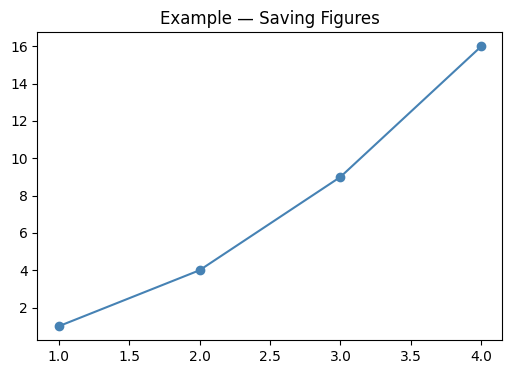

In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot([1, 2, 3, 4], [1, 4, 9, 16], 'o-', color='steelblue')
ax.set_title('Example — Saving Figures')

# savefig MUST come BEFORE plt.show() — after show() the figure is cleared

# PNG  → raster, good for web/presentations (use dpi for resolution)
fig.savefig('my_plot.png', dpi=150, bbox_inches='tight')

# SVG  → vector, scales infinitely, great for papers/print
fig.savefig('my_plot.svg', bbox_inches='tight')

# PDF  → vector, best for LaTeX/academic papers
fig.savefig('my_plot.pdf', bbox_inches='tight')

print("Figures saved!")
plt.show()

# bbox_inches='tight' → trims extra whitespace around the figure

---
---
# 🎨 Seaborn
## 10. Setup & Sample Datasets
> Seaborn comes with built-in datasets — perfect for learning.

In [10]:
# Seaborn works best with pandas DataFrames
# Load built-in datasets
tips    = sns.load_dataset('tips')      # Restaurant tips
iris    = sns.load_dataset('iris')      # Famous flower dataset
titanic = sns.load_dataset('titanic')   # Titanic passengers
penguins = sns.load_dataset('penguins') # Palmer penguins

print("=== Tips Dataset ===")
print(tips.head())
print("\nShape:", tips.shape)
print("Columns:", list(tips.columns))

=== Tips Dataset ===
   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4

Shape: (244, 7)
Columns: ['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size']


---
## 11. Distribution Plots
> Understanding how data is spread.

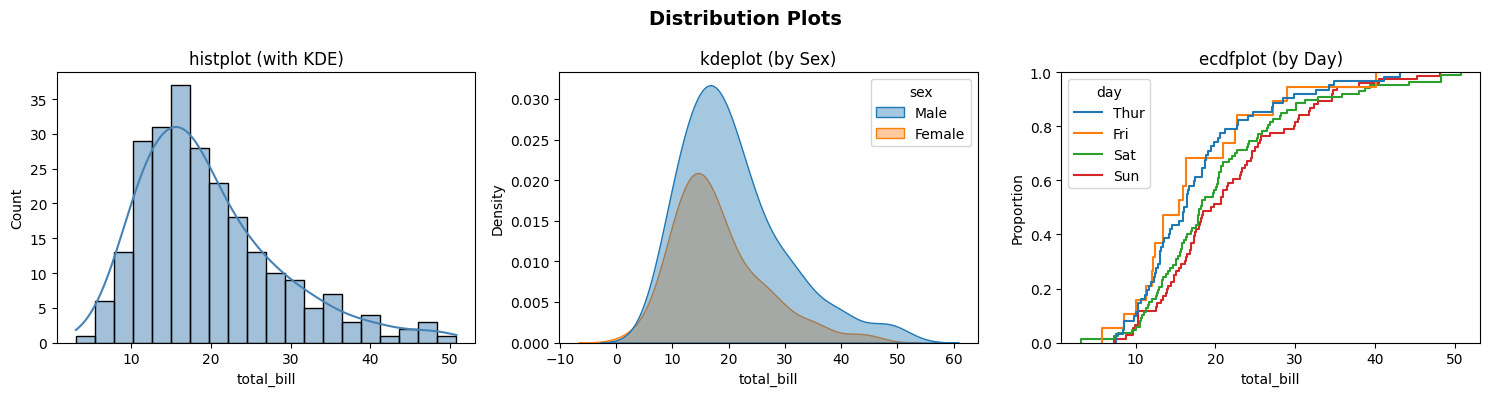

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle('Distribution Plots', fontsize=14, fontweight='bold')

# ── histplot  → histogram + optional KDE curve ──
sns.histplot(data=tips, x='total_bill',
             bins=20,
             kde=True,           # Overlay a smooth density curve
             color='steelblue',
             ax=axes[0])
axes[0].set_title('histplot (with KDE)')

# ── kdeplot  → smooth density curve only ──
sns.kdeplot(data=tips, x='total_bill',
            hue='sex',           # Separate curves by category
            fill=True,           # Fill under the curve
            alpha=0.4,
            ax=axes[1])
axes[1].set_title('kdeplot (by Sex)')

# ── ecdfplot  → Empirical Cumulative Distribution Function ──
sns.ecdfplot(data=tips, x='total_bill',
             hue='day',
             ax=axes[2])
axes[2].set_title('ecdfplot (by Day)')

plt.tight_layout()
plt.show()

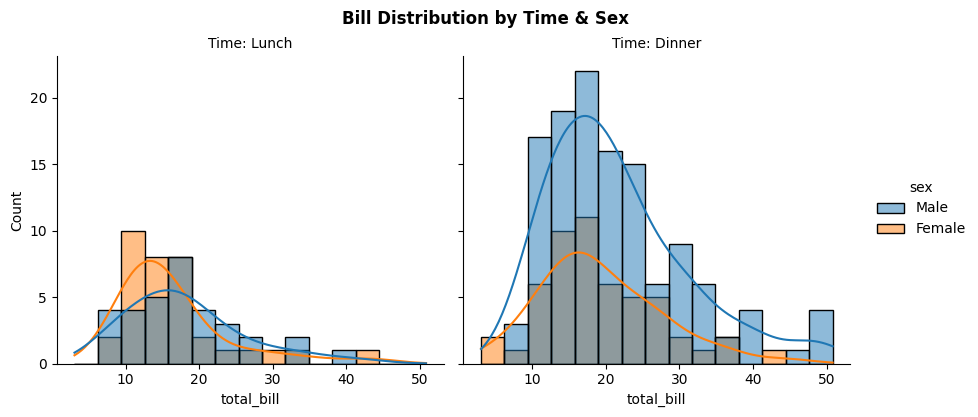

In [12]:
# ── displot  → Figure-level version (creates its own figure with facets) ──
g = sns.displot(data=tips, x='total_bill',
                col='time',        # Separate column for each time (Lunch/Dinner)
                hue='sex',
                kde=True,
                bins=15,
                height=4, aspect=1.1)
g.set_titles('Time: {col_name}')   # Custom subplot titles
g.figure.suptitle('Bill Distribution by Time & Sex', y=1.03, fontweight='bold')
plt.show()

---
## 12. Categorical Plots
> Comparing data across categories — Seaborn shines here.

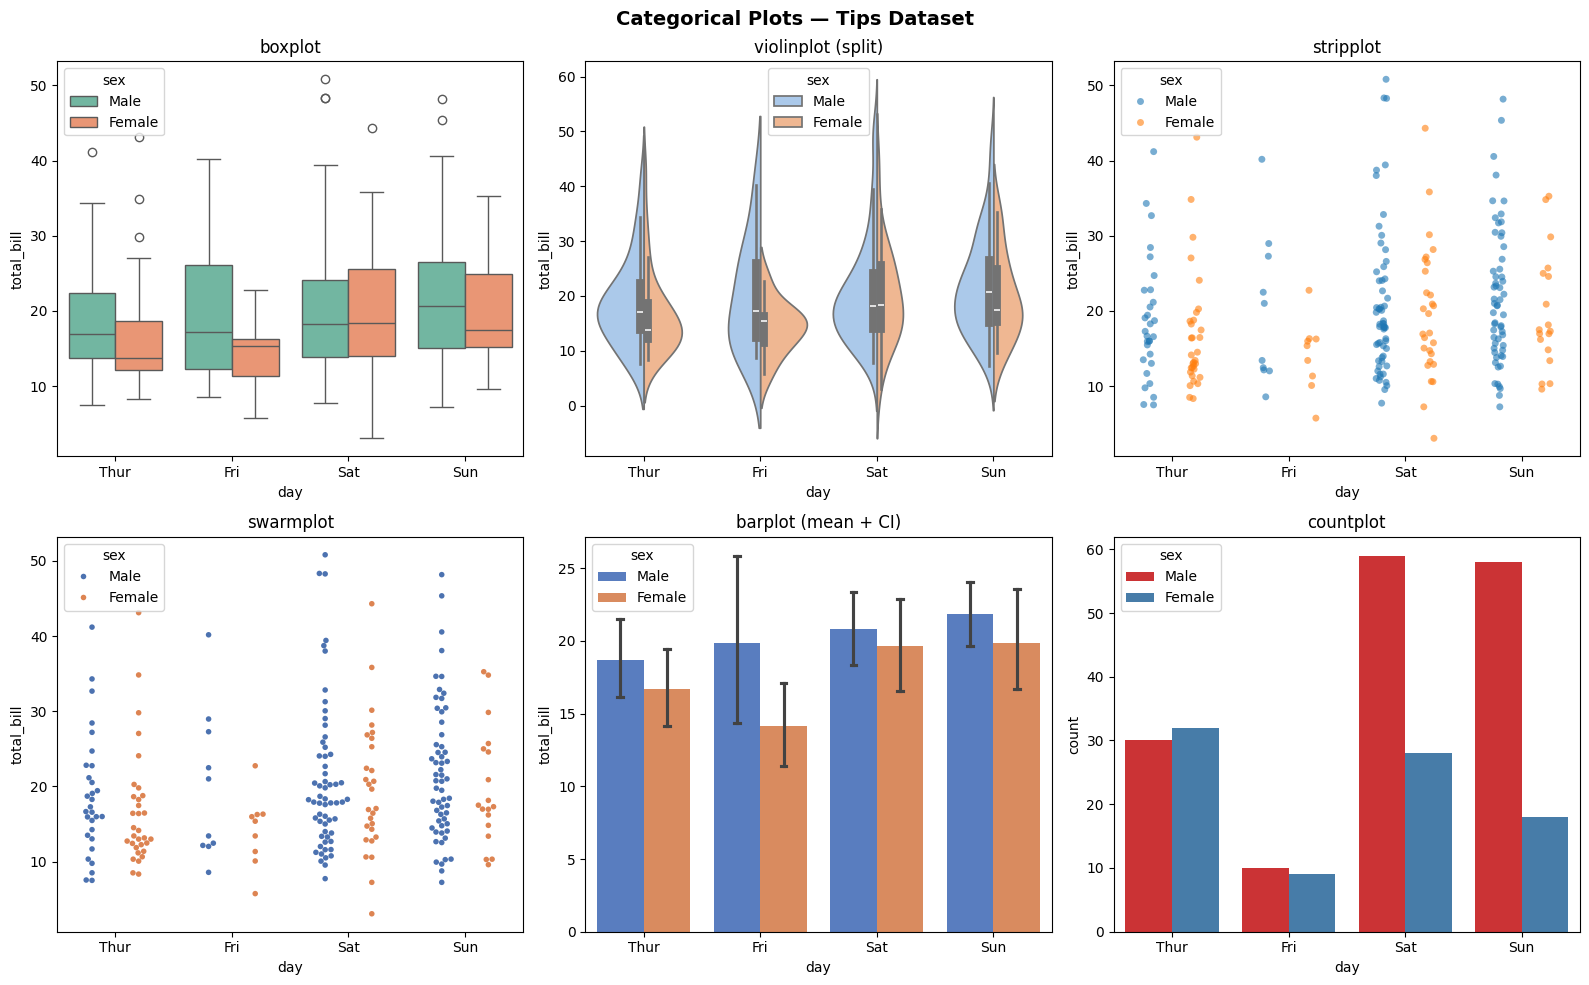

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Categorical Plots — Tips Dataset', fontsize=14, fontweight='bold')

# ── boxplot → shows median, IQR, and outliers ──
sns.boxplot(data=tips, x='day', y='total_bill',
            hue='sex', palette='Set2', ax=axes[0, 0])
axes[0, 0].set_title('boxplot')

# ── violinplot → box + KDE (shows distribution shape) ──
sns.violinplot(data=tips, x='day', y='total_bill',
               hue='sex', split=True,   # Split violin by hue
               palette='pastel', ax=axes[0, 1])
axes[0, 1].set_title('violinplot (split)')

# ── stripplot → scatter for categorical x ──
sns.stripplot(data=tips, x='day', y='total_bill',
              hue='sex', dodge=True, jitter=True,  # jitter avoids overplotting
              alpha=0.6, ax=axes[0, 2])
axes[0, 2].set_title('stripplot')

# ── swarmplot → non-overlapping strip plot ──
sns.swarmplot(data=tips, x='day', y='total_bill',
              hue='sex', dodge=True,
              palette='deep', size=4, ax=axes[1, 0])
axes[1, 0].set_title('swarmplot')

# ── barplot → shows mean + confidence interval ──
sns.barplot(data=tips, x='day', y='total_bill',
            hue='sex', palette='muted',
            capsize=0.1,              # Width of error bar caps
            ax=axes[1, 1])
axes[1, 1].set_title('barplot (mean + CI)')

# ── countplot → count of items per category ──
sns.countplot(data=tips, x='day',
              hue='sex', palette='Set1', ax=axes[1, 2])
axes[1, 2].set_title('countplot')

plt.tight_layout()
plt.show()

---
## 13. Relationship Plots
> Exploring how two or more variables relate.

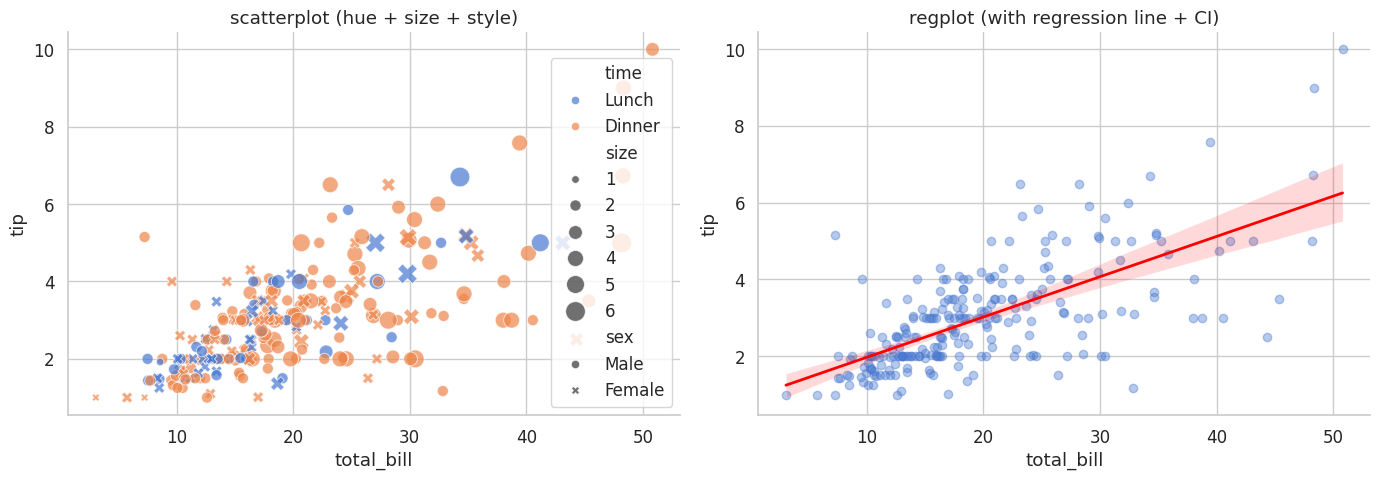

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── scatterplot → with hue, size, and style encodings ──
sns.scatterplot(data=tips, x='total_bill', y='tip',
                hue='time',      # Color by time (Lunch/Dinner)
                size='size',     # Marker size by party size
                style='sex',     # Marker shape by sex
                sizes=(30, 200), # Min/max marker size range
                alpha=0.7,
                ax=axes[0])
axes[0].set_title('scatterplot (hue + size + style)')

# ── regplot → scatter + linear regression line ──
sns.regplot(data=tips, x='total_bill', y='tip',
            scatter_kws={'alpha': 0.4},
            line_kws={'color': 'red', 'linewidth': 2},
            ax=axes[1])
axes[1].set_title('regplot (with regression line + CI)')

plt.tight_layout()
plt.show()

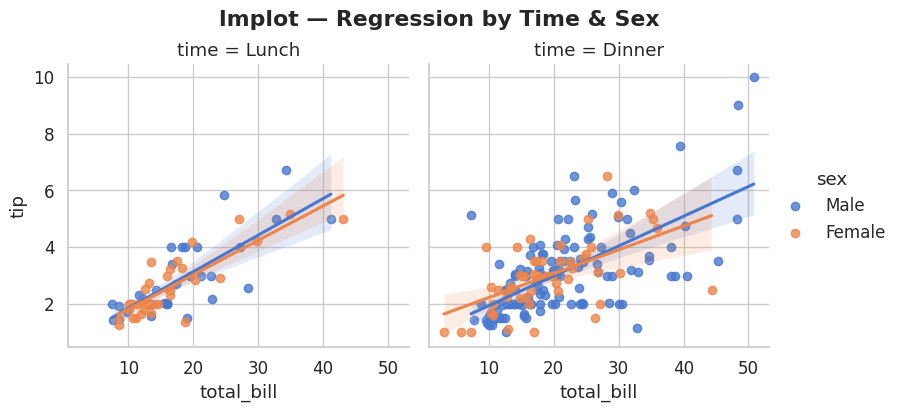

In [18]:
# ── lmplot → figure-level regplot with facet support ──
g = sns.lmplot(data=tips, x='total_bill', y='tip',
               col='time',       # Separate columns per time
               hue='sex',
               height=4, aspect=1)
g.figure.suptitle('lmplot — Regression by Time & Sex', y=1.03, fontweight='bold')
plt.show()

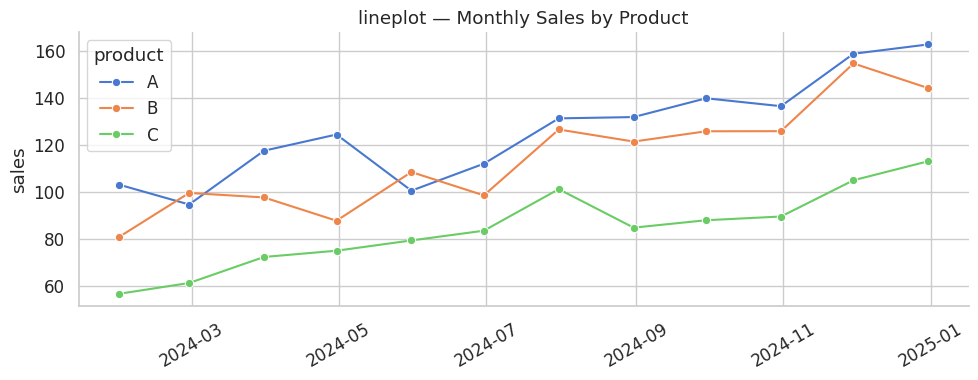

In [19]:
# ── lineplot → with confidence interval (great for time-series) ──
rng = np.random.default_rng(42)
dates = pd.date_range('2024-01', periods=12, freq='ME')
sales = pd.DataFrame({
    'month'  : list(dates) * 3,
    'sales'  : np.concatenate([
        rng.normal(100 + np.arange(12)*5, 10),
        rng.normal(80  + np.arange(12)*6, 12),
        rng.normal(60  + np.arange(12)*4, 8),
    ]),
    'product': ['A']*12 + ['B']*12 + ['C']*12
})

fig, ax = plt.subplots(figsize=(10, 4))
sns.lineplot(data=sales, x='month', y='sales', hue='product',
             marker='o', dashes=False, ax=ax)
ax.set_title('lineplot — Monthly Sales by Product')
ax.set_xlabel('')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

---
## 14. Heatmap & Correlation
> The go-to plot for showing correlation matrices and 2D data grids.

Correlation Matrix:
               sepal_length  sepal_width  petal_length  petal_width
sepal_length          1.00        -0.12          0.87         0.82
sepal_width          -0.12         1.00         -0.43        -0.37
petal_length          0.87        -0.43          1.00         0.96
petal_width           0.82        -0.37          0.96         1.00


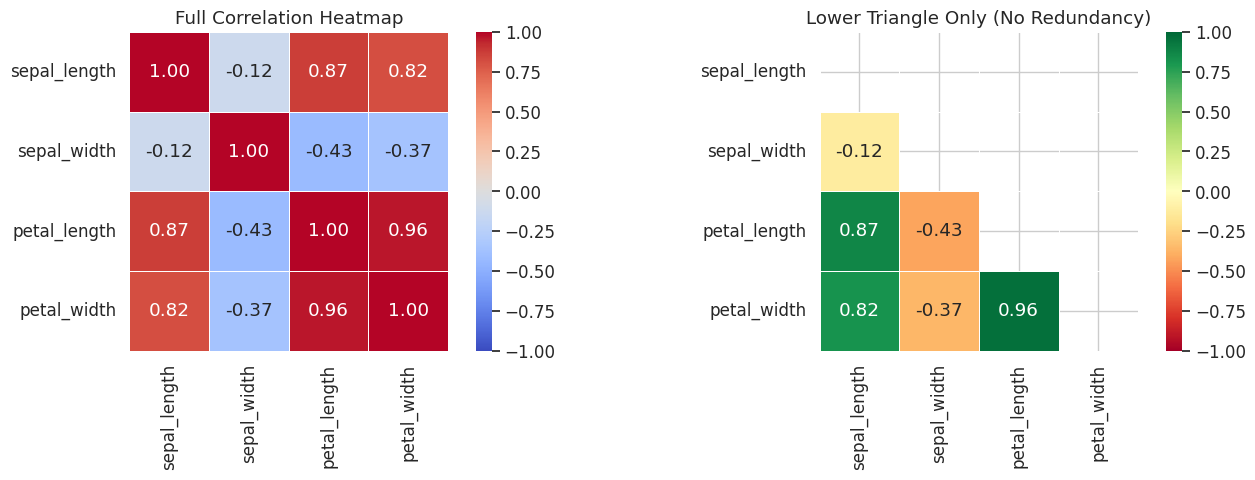

In [20]:
# ── Correlation Heatmap ──
# Step 1: Compute correlation matrix from numeric columns
numeric_cols = iris.select_dtypes(include=np.number)
corr_matrix  = numeric_cols.corr()   # Values between -1 (negative) and +1 (positive)

print("Correlation Matrix:\n", corr_matrix.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Full heatmap
sns.heatmap(corr_matrix,
            annot=True,          # Show values in cells
            fmt='.2f',           # Format to 2 decimal places
            cmap='coolwarm',     # Color: blue=negative, red=positive
            center=0,            # Center colorbar at 0
            vmin=-1, vmax=1,     # Fix scale to [-1, 1]
            linewidths=0.5,      # Add cell borders
            square=True,
            ax=axes[0])
axes[0].set_title('Full Correlation Heatmap')

# Masked heatmap — upper triangle only (avoids redundancy)
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))  # Upper triangle mask
sns.heatmap(corr_matrix,
            mask=mask,
            annot=True, fmt='.2f',
            cmap='RdYlGn',
            center=0, vmin=-1, vmax=1,
            linewidths=0.5, square=True,
            ax=axes[1])
axes[1].set_title('Lower Triangle Only (No Redundancy)')

plt.tight_layout()
plt.show()

/tmp/ipykernel_1913/3854882825.py:3: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot = tips.pivot_table(values='tip', index='day', columns='time', aggfunc='mean')


Pivot table:
 time  Lunch  Dinner
day                
Thur   2.77    3.00
Fri    2.38    2.94
Sat     NaN    2.99
Sun     NaN    3.26


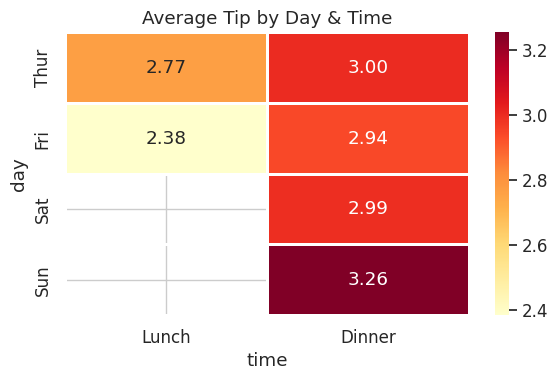

In [21]:
# ── Heatmap for 2D Grid Data ──
# (e.g., pivot table: how avg tip varies by day and time)
pivot = tips.pivot_table(values='tip', index='day', columns='time', aggfunc='mean')
print("Pivot table:\n", pivot.round(2))

fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(pivot, annot=True, fmt='.2f', cmap='YlOrRd',
            linewidths=1, ax=ax)
ax.set_title('Average Tip by Day & Time')
plt.tight_layout()
plt.show()

---
## 15. Pair Plot
> Explore **all pairwise relationships** at once — essential for EDA.

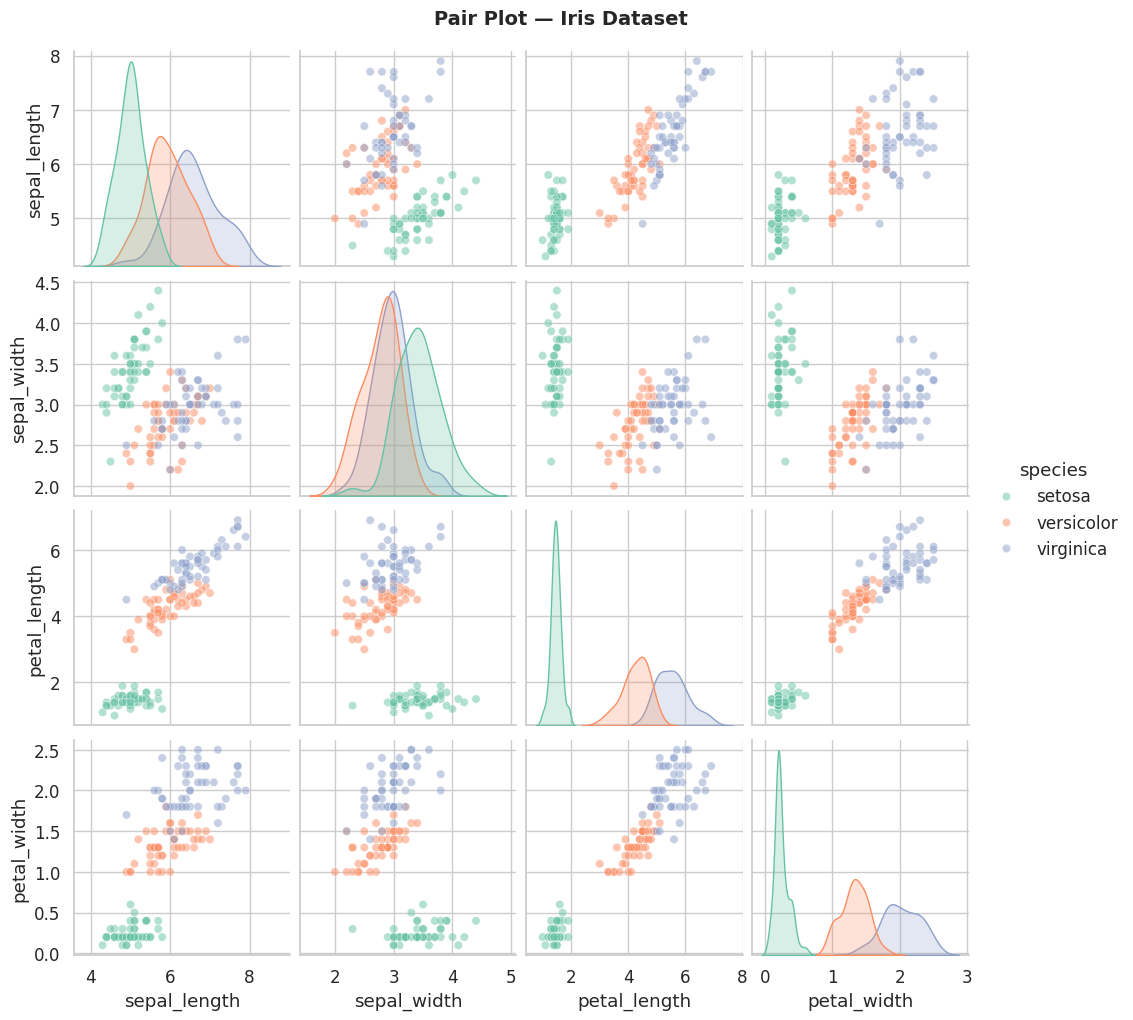

In [22]:
# pairplot creates a grid:
# - Diagonal    = distribution of each variable
# - Off-diagonal = scatter plot of each pair

g = sns.pairplot(iris,
                 hue='species',          # Color by species (categorical)
                 diag_kind='kde',        # Diagonal: KDE curve (or 'hist')
                 plot_kws={'alpha': 0.5},
                 palette='Set2')
g.figure.suptitle('Pair Plot — Iris Dataset', y=1.02, fontsize=14, fontweight='bold')
plt.show()

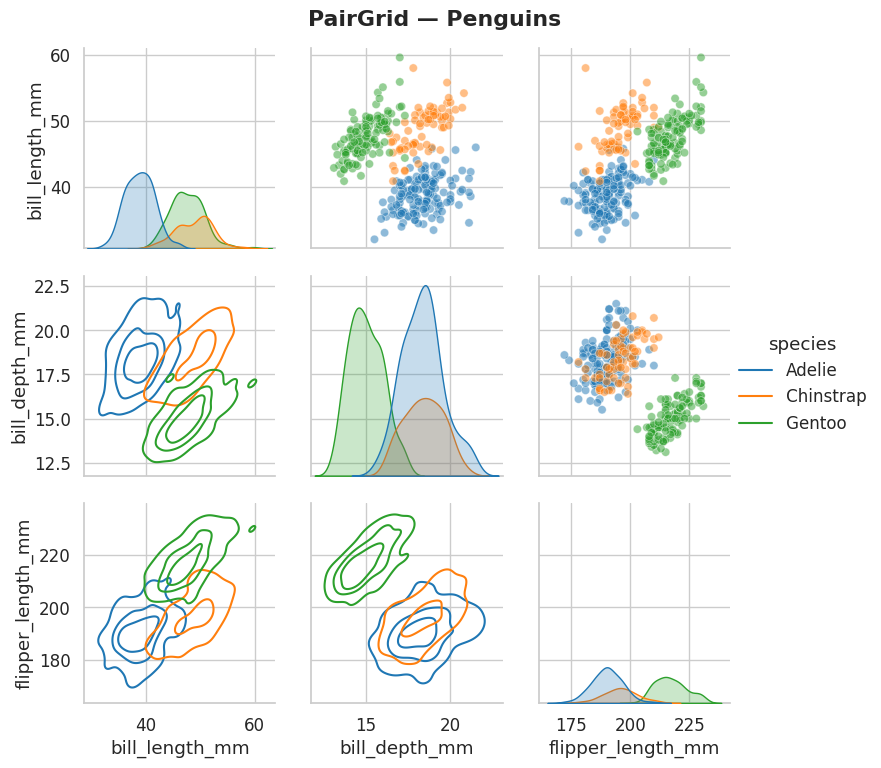

In [23]:
# ── PairGrid → manual control over what goes in each section ──
g = sns.PairGrid(penguins.dropna(), hue='species', palette='tab10',
                 vars=['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm'])

g.map_upper(sns.scatterplot, alpha=0.5)   # Upper triangle: scatter
g.map_diag(sns.kdeplot, fill=True)        # Diagonal: KDE
g.map_lower(sns.kdeplot, levels=4)        # Lower triangle: 2D KDE contours
g.add_legend()
g.figure.suptitle('PairGrid — Penguins', y=1.02, fontweight='bold')
plt.show()

---
## 16. Styling & Themes
> Make your Seaborn plots look great with minimal effort.

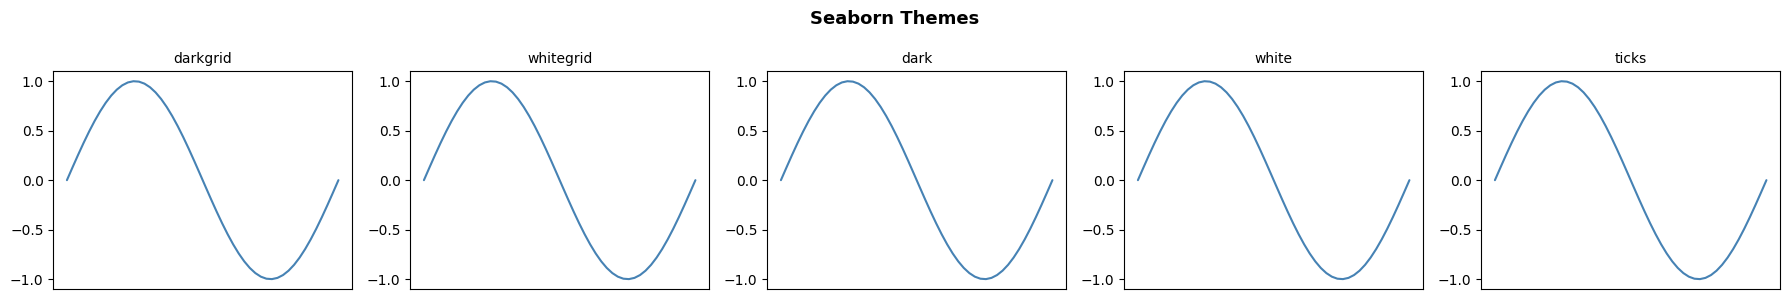

In [14]:
# ── Seaborn Themes (style) ──
# Options: 'darkgrid', 'whitegrid', 'dark', 'white', 'ticks'

themes = ['darkgrid', 'whitegrid', 'dark', 'white', 'ticks']
fig, axes = plt.subplots(1, 5, figsize=(18, 3))

for ax, theme in zip(axes, themes):
    with sns.axes_style(theme):         # Apply temporarily
        x = np.linspace(0, 2*np.pi, 50)
        ax.plot(x, np.sin(x), color='steelblue')
        ax.set_title(theme, fontsize=10)
        ax.set_xticks([])

fig.suptitle('Seaborn Themes', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

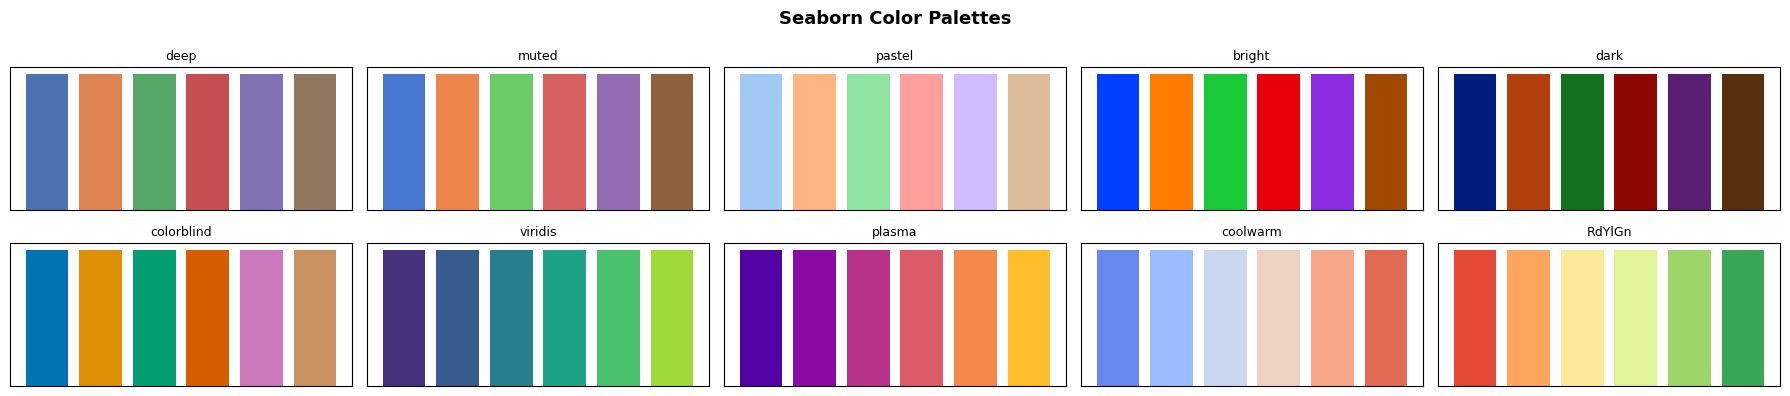

In [15]:
# ── Color Palettes ──
# Seaborn has great built-in palettes

palettes = ['deep', 'muted', 'pastel', 'bright', 'dark', 'colorblind',
            'viridis', 'plasma', 'coolwarm', 'RdYlGn']

fig, axes = plt.subplots(2, 5, figsize=(18, 4))
axes = axes.flatten()

for ax, pal in zip(axes, palettes):
    colors = sns.color_palette(pal, 6)
    for i, color in enumerate(colors):
        ax.bar(i, 1, color=color)
    ax.set_title(pal, fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])

fig.suptitle('Seaborn Color Palettes', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Apply a palette globally:
# sns.set_palette('muted')
# Or use in a plot:
# sns.barplot(..., palette='viridis')

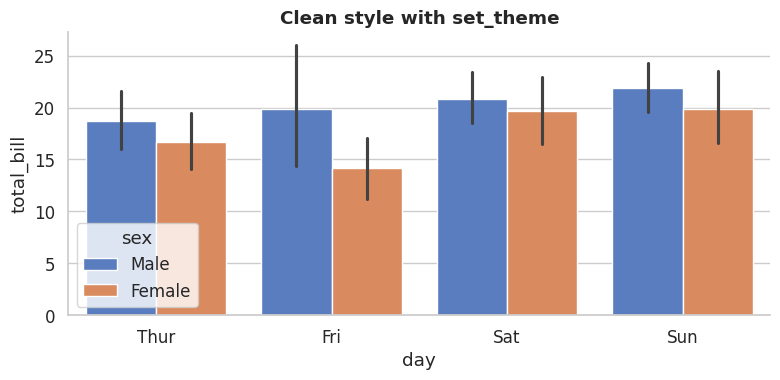

In [16]:
# ── sns.set_theme  → Global settings in one call ──
sns.set_theme(
    style='whitegrid',    # Background style
    palette='muted',      # Color palette
    font_scale=1.1,       # Scale all font sizes
    rc={'axes.spines.top': False,     # Remove top border
        'axes.spines.right': False}   # Remove right border
)

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=tips, x='day', y='total_bill', hue='sex', ax=ax)
ax.set_title('Clean style with set_theme', fontweight='bold')
plt.tight_layout()
plt.show()

# Reset to default:
# sns.reset_defaults()

---
## 17. Practical Mini-Projects

In [ ]:
# ════════════════════════════════════════════════════════
# 📊 Project 1: Complete Exploratory Data Analysis (EDA)
#              on the Tips dataset
# ════════════════════════════════════════════════════════
tips = sns.load_dataset('tips')
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.0)

fig = plt.figure(figsize=(16, 12))
fig.suptitle('Restaurant Tips — Full EDA Dashboard', fontsize=16,
             fontweight='bold', y=0.98)

# ── Row 1: Distributions ──
ax1 = fig.add_subplot(3, 3, 1)
sns.histplot(tips['total_bill'], bins=20, kde=True, ax=ax1)
ax1.set_title('Total Bill Distribution')

ax2 = fig.add_subplot(3, 3, 2)
sns.histplot(tips['tip'], bins=20, kde=True, color='coral', ax=ax2)
ax2.set_title('Tip Distribution')

ax3 = fig.add_subplot(3, 3, 3)
tips['tip_pct'] = tips['tip'] / tips['total_bill'] * 100
sns.histplot(tips['tip_pct'], bins=20, kde=True, color='seagreen', ax=ax3)
ax3.set_title('Tip % Distribution')

# ── Row 2: Category Comparisons ──
ax4 = fig.add_subplot(3, 3, 4)
sns.boxplot(data=tips, x='day', y='total_bill', hue='sex', ax=ax4)
ax4.set_title('Bill by Day & Sex')
ax4.legend(title='Sex', loc='upper left', fontsize=8)

ax5 = fig.add_subplot(3, 3, 5)
sns.barplot(data=tips, x='day', y='tip_pct', hue='time',
            capsize=0.1, ax=ax5)
ax5.set_title('Avg Tip % by Day & Time')
ax5.set_ylabel('Tip %')

ax6 = fig.add_subplot(3, 3, 6)
sns.countplot(data=tips, x='day', hue='smoker', palette='Set2', ax=ax6)
ax6.set_title('Customer Count by Day')

# ── Row 3: Relationships ──
ax7 = fig.add_subplot(3, 3, 7)
sns.scatterplot(data=tips, x='total_bill', y='tip',
                hue='size', size='size',
                sizes=(30, 200), alpha=0.7, ax=ax7)
ax7.set_title('Bill vs Tip (by Party Size)')

ax8 = fig.add_subplot(3, 3, 8)
pivot = tips.pivot_table(values='tip_pct', index='day',
                         columns='time', aggfunc='mean')
sns.heatmap(pivot, annot=True, fmt='.1f', cmap='YlOrRd',
            linewidths=1, ax=ax8)
ax8.set_title('Avg Tip % Heatmap')

ax9 = fig.add_subplot(3, 3, 9)
sns.violinplot(data=tips, x='time', y='tip',
               hue='sex', split=True, palette='pastel', ax=ax9)
ax9.set_title('Tip by Time & Sex')

plt.tight_layout()
plt.savefig('eda_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()
print("Dashboard saved as eda_dashboard.png")

In [ ]:
# ════════════════════════════════════════════════
# 📈 Project 2: Stock Price Dashboard
# ════════════════════════════════════════════════
rng = np.random.default_rng(99)
sns.set_theme(style='darkgrid', palette='tab10')

# Generate synthetic stock data for 3 companies
days = 252   # ~1 trading year
dates = pd.date_range('2024-01-01', periods=days, freq='B')  # Business days

def simulate_stock(start, mu, sigma):
    """Simulate stock price using geometric Brownian motion."""
    returns = rng.normal(mu, sigma, days)
    return start * np.cumprod(1 + returns)

prices = pd.DataFrame({
    'Date'   : dates,
    'TechCo' : simulate_stock(100, 0.0008, 0.018),
    'BankCo' : simulate_stock(80,  0.0003, 0.012),
    'RetailCo': simulate_stock(60, 0.0005, 0.022),
})
prices.set_index('Date', inplace=True)

# Normalize so all start at 100 (easy comparison)
normalized = prices / prices.iloc[0] * 100

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle('Stock Price Dashboard (2024)', fontsize=15, fontweight='bold')

# Top-left: Normalized price
for col in normalized.columns:
    axes[0, 0].plot(normalized.index, normalized[col], label=col, linewidth=1.5)
axes[0, 0].axhline(100, color='black', linestyle='--', linewidth=0.8, alpha=0.5)
axes[0, 0].set_title('Normalized Price (Base=100)')
axes[0, 0].legend()
axes[0, 0].set_ylabel('Index')

# Top-right: Daily returns distribution
returns = prices.pct_change().dropna() * 100
for col in returns.columns:
    sns.kdeplot(returns[col], label=col, fill=True, alpha=0.3, ax=axes[0, 1])
axes[0, 1].axvline(0, color='black', linewidth=0.8)
axes[0, 1].set_title('Daily Returns Distribution')
axes[0, 1].set_xlabel('Return (%)')
axes[0, 1].legend()

# Bottom-left: Correlation heatmap of returns
corr = returns.corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square=True, ax=axes[1, 0])
axes[1, 0].set_title('Return Correlation Heatmap')

# Bottom-right: Volatility (rolling 20-day std)
volatility = returns.rolling(20).std()
for col in volatility.columns:
    axes[1, 1].plot(volatility.index, volatility[col], label=col, linewidth=1.5)
axes[1, 1].set_title('Rolling 20-Day Volatility')
axes[1, 1].set_ylabel('Std Dev of Returns (%)')
axes[1, 1].legend()

plt.tight_layout()
plt.savefig('stock_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()
print("Stock dashboard saved as stock_dashboard.png")

---
## ⚡ Quick Reference Cheatsheet

### Matplotlib

| Task | Code |
|---|---|
| Create figure | `fig, ax = plt.subplots(figsize=(w, h))` |
| Multiple plots | `fig, axes = plt.subplots(nrows, ncols)` |
| Line plot | `ax.plot(x, y, color=, lw=, ls=, label=)` |
| Scatter plot | `ax.scatter(x, y, s=, c=, alpha=, marker=)` |
| Bar chart | `ax.bar(x, height)` / `ax.barh(y, width)` |
| Histogram | `ax.hist(data, bins=, density=, alpha=)` |
| Pie chart | `ax.pie(sizes, labels=, autopct=)` |
| Title / labels | `ax.set_title()` / `ax.set_xlabel/ylabel()` |
| Axis limits | `ax.set_xlim(a, b)` / `ax.set_ylim(a, b)` |
| Legend | `ax.legend(loc=)` |
| Grid | `ax.grid(True, alpha=)` |
| H/V lines | `ax.axhline(y)` / `ax.axvline(x)` |
| Annotations | `ax.annotate('text', xy=, xytext=, arrowprops=)` |
| Save | `fig.savefig('file.png', dpi=150, bbox_inches='tight')` |
| Styles | `plt.style.use('seaborn-v0_8-darkgrid')` |

### Seaborn

| Plot Type | Function | Best For |
|---|---|---|
| **Distribution** | `histplot` | Histogram + optional KDE |
| | `kdeplot` | Smooth density curve |
| | `ecdfplot` | Cumulative distribution |
| | `displot` | Figure-level, facets |
| **Categorical** | `boxplot` | Median, IQR, outliers |
| | `violinplot` | Box + density shape |
| | `stripplot` | Scatter for categorical x |
| | `swarmplot` | Non-overlapping strip |
| | `barplot` | Mean + confidence interval |
| | `countplot` | Count per category |
| **Relationship** | `scatterplot` | Two numeric vars |
| | `regplot` | Scatter + regression line |
| | `lmplot` | regplot with facets |
| | `lineplot` | Line with CI band |
| **Matrix** | `heatmap` | Correlation / 2D grid |
| **Multi-var** | `pairplot` | All pairs at once |
| | `PairGrid` | Custom pair grid |
| **Themes** | `sns.set_theme()` | Style + palette + font |
| | `sns.axes_style()` | Temporary style |

---
### 💡 Key Takeaways
- Always use the **Object-Oriented interface** (`fig, ax = plt.subplots()`) for anything beyond a quick draft
- Call `plt.tight_layout()` before `plt.show()` to prevent clipped labels
- Call `fig.savefig()` **before** `plt.show()` — after `show()` the figure is cleared
- Seaborn's `hue`, `size`, and `style` parameters let you encode **up to 5 variables** in one plot
- Use `heatmap` with a masked upper triangle to avoid redundancy in correlation matrices
- `pairplot` is the fastest way to get an overview of a new dataset
- Set `bbox_inches='tight'` and high `dpi` (150+) when saving figures for reports